In [1]:

from google.colab import files

uploaded = files.upload()


Saving creditcard.csv to creditcard.csv


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv("creditcard.csv")
df.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
df.shape


(284807, 31)

In [6]:
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [7]:
df["Class"].value_counts()

,count
Class,
0,284315
1,492


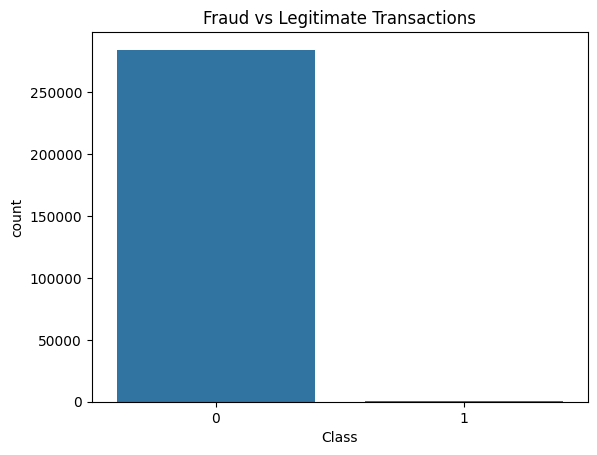

In [8]:

sns.countplot(data=df, x="Class")
plt.title("Fraud vs Legitimate Transactions")
plt.show()


In [9]:

df.groupby("Class")["Amount"].describe()


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


In [10]:
X = df.drop("Class", axis=1)
y = df["Class"]


In [11]:
print(X.shape)
print(y.shape)

(284807, 30)
(284807,)


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)


Training: (227845, 30)
Testing: (56962, 30)


In [13]:

fraud = (y_train == 1).sum()
legitimate = (y_train == 0).sum()

weight = legitimate / fraud

print("Fraud:", fraud)
print("Legitimate:", legitimate)
print("Class weight:", weight)


Fraud: 394
Legitimate: 227451
Class weight: 577.2868020304569


In [14]:

from xgboost import XGBClassifier

model = XGBClassifier(n_estimators=100,max_depth=4, learning_rate=0.1,scale_pos_weight=weight,eval_metric="logloss",random_state=42, n_jobs=-1)

model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


In [15]:

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import average_precision_score

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))
print("PR-AUC:", average_precision_score(y_test, y_prob))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.35      0.87      0.49        98

    accuracy                           1.00     56962
   macro avg       0.67      0.93      0.75     56962
weighted avg       1.00      1.00      1.00     56962

PR-AUC: 0.8327227729701703
Confusion Matrix:
[[56703   161]
 [   13    85]]


In [16]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred_new = (y_prob >= 0.7).astype(int)

print(classification_report(y_test, y_pred_new))
print(confusion_matrix(y_test, y_pred_new))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.54      0.86      0.66        98

    accuracy                           1.00     56962
   macro avg       0.77      0.93      0.83     56962
weighted avg       1.00      1.00      1.00     56962

[[56792    72]
 [   14    84]]


In [17]:

import joblib

joblib.dump(model, "fraud_model.pkl")
joblib.dump(X_train.columns.tolist(), "features.pkl")

print("Files saved successfully!")


Files saved successfully!


In [18]:

from google.colab import files

files.download("fraud_model.pkl")
files.download("features.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>